# BrushCue Example: Triangle Blur

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/triangle_blur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/triangle-blur

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


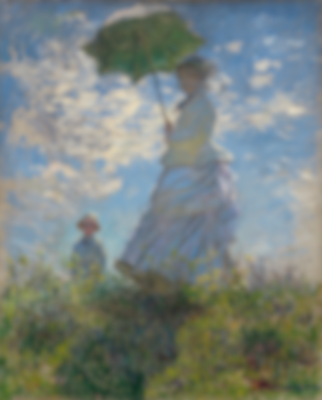

In [1]:
import io
from PIL import Image

import brushcue as bc

blur_size = 15
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
blurred = input_image.box_blur(blur_size).box_blur(blur_size).crop(input_bounds)
graph = input_image.spacial_effect_shader(
    "let original = sample(position);\nlet blurred = sampleBlurred(position);\nreturn vec4<f32>(blurred.rgb, original.a);",
    "",
    0.0,
    bc.Dictionary.create().add("blurred", blurred),
    bc.ColorRepresentation.srgb(),
).crop(input_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
